# Experimento 8 — H2O AutoML

Mesmas 14 features e mesmo histórico do cenário principal do Exp. 7, sem Elo.
Target = ScoreA − ScoreB; TeamA é o menor ID. Previsões permanecem margens em pontos.
O H2O escolhe o leader pela **RMSE da CV interna**. A métrica oficial externa é a
**Logistic Brier de `src/metrics.py`**, combinando M/W e dando peso igual aos cinco anos.


## Configuração

Instale `requirements-h2o.txt` no ambiente do kernel (na raiz: `python -m pip install -r requirements-h2o.txt`).
É necessário Java disponível para o H2O. Neste projeto, a integração foi testada no kernel `.venv`.
Não há instalação automática nem salvamento de modelos binários pelo notebook.


In [12]:
from pathlib import Path
import sys
import json
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display

pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "raw_data").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Pasta raw_data não encontrada.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.data_processing import carregar_dados, preparar_seeds, organizar_jogos
from src.features import (
    adicionar_seeds, calcular_estatisticas_agregadas, adicionar_estatisticas,
    ESTATISTICAS_DETALHADAS, calcular_estatisticas_detalhadas, adicionar_estatisticas_detalhadas,
)
from src.automl_h2o import (
    inicializar_h2o, avaliar_temporadas_h2o, treinar_automl, limpar_execucao, AdaptadorH2O,
)
from src.submission import preparar_confrontos, prever_confrontos, salvar_submission

EXPERIMENTO = "exp8_h2o_automl"
FEATURES_EXP4 = ["SeedDif", "WinRateDiff", "AvgPointsForDiff", "AvgPointsAgainstDiff", "OppWinRateDiff"]
FEATURES = [*FEATURES_EXP4, *[nome + "Diff" for nome in ESTATISTICAS_DETALHADAS]]
INICIO_DETALHADO = {"M": 2003, "W": 2010}
ANOS_VALIDACAO = list(range(2021, 2026))
TEMPORADA_PREVISAO = 2026
LIMITE_DAYNUM_PREVISAO = 134
CATEGORIAS = {"M": "Masculino", "W": "Feminino"}
SEED = 42
MAX_MODELS = 100
N_FOLDS_INTERNOS = 5
N_THREADS = 2
MAX_MEM_SIZE = "4G"

REFERENCIA_EXP7 = json.loads(r'''{"features": ["SeedDif", "WinRateDiff", "AvgPointsForDiff", "AvgPointsAgainstDiff", "OppWinRateDiff", "FGPercentageDiff", "ThreePointPercentageDiff", "FTPercentageDiff", "AssistsPerGameDiff", "OffensiveReboundsPerGameDiff", "DefensiveReboundsPerGameDiff", "TurnoversPerGameDiff", "StealsPerGameDiff", "BlocksPerGameDiff"], "anos_validacao": [2021, 2022, 2023, 2024, 2025], "inicio_detalhado": {"M": 2003, "W": 2010}, "versoes": {"numpy": "2.2.6", "pandas": "2.3.2", "scikit-learn": "1.7.1", "xgboost": "3.0.5", "optuna": "4.9.0"}, "cenario": "Exp7 disponivel", "medias": {"linear": 0.07235902247317808, "random_forest": 0.07059117078512692, "xgboost": 0.06962912060600238}, "fonte": "notebooks/features_incrementais/exp7_features_detalhadas.ipynb: registro salvo", "sha256_notebook": "ebfa70c730e9b02c745e466e8cacde67a33136e365143c826e5ba5257823bf37"}''')

assert FEATURES == REFERENCIA_EXP7["features"]
assert ANOS_VALIDACAO == REFERENCIA_EXP7["anos_validacao"]
assert INICIO_DETALHADO == REFERENCIA_EXP7["inicio_detalhado"]


## Preparação dos dados/features

Reutilizamos as funções do `src/` e o recorte do Exp. 7: dados regulares da própria
temporada, anteriores ao primeiro dia NCAA; em 2026, DayNum < 134.
As estatísticas detalhadas femininas têm cobertura incompleta em 2010–2012;
mantemos a mesma definição por jogo disponível e a auditoria do experimento anterior.


In [13]:
dados = {
    categoria: carregar_dados(raiz / "raw_data", categoria, incluir_regular=True, incluir_detalhado=True)
    for categoria in CATEGORIAS
}
assert set(dados["M"]["times"]["TeamID"]).isdisjoint(set(dados["W"]["times"]["TeamID"]))
seeds, estatisticas, detalhadas, jogos, limites, coberturas = {}, {}, {}, {}, {}, []
chaves_jogo = ["Season", "DayNum", "WTeamID", "LTeamID"]
for categoria, base in dados.items():
    torneios = base["resultados"].loc[base["resultados"]["Season"] < TEMPORADA_PREVISAO].copy()
    limites[categoria] = torneios.groupby("Season")["DayNum"].min().to_dict()
    limites[categoria][TEMPORADA_PREVISAO] = LIMITE_DAYNUM_PREVISAO
    raw_detalhes = base["temporada_regular_detalhada"]
    assert raw_detalhes["Season"].min() == INICIO_DETALHADO[categoria]
    anos = set(raw_detalhes["Season"]) & set(limites[categoria])
    assert set([*ANOS_VALIDACAO, TEMPORADA_PREVISAO]).issubset(anos)
    regulares = base["temporada_regular"].loc[base["temporada_regular"]["Season"].isin(anos)].copy()
    detalhes = raw_detalhes.loc[raw_detalhes["Season"].isin(anos)].copy()
    ids = set(base["times"]["TeamID"])
    for tabela in [regulares, detalhes]:
        assert (tabela["DayNum"] < tabela["Season"].map(limites[categoria])).all()
        assert tabela.merge(torneios[chaves_jogo], on=chaves_jogo).empty
        assert tabela["WTeamID"].isin(ids).all() and tabela["LTeamID"].isin(ids).all()
    conferidos = detalhes.merge(regulares[chaves_jogo + ["WScore", "LScore"]],
        on=chaves_jogo, how="left", suffixes=("", "Compact"), validate="one_to_one", indicator=True)
    assert conferidos["_merge"].eq("both").all()
    for placar in ["WScore", "LScore"]:
        np.testing.assert_array_equal(conferidos[placar], conferidos[placar + "Compact"])

    cobertura = regulares.groupby("Season").size().rename("JogosCompact").to_frame()
    cobertura["JogosDetalhados"] = detalhes.groupby("Season").size()
    cobertura["SemDetalhes"] = cobertura["JogosCompact"] - cobertura["JogosDetalhados"]
    cobertura["Cobertura"] = cobertura["JogosDetalhados"] / cobertura["JogosCompact"]
    cobertura["UltimoDayNumDetalhado"] = detalhes.groupby("Season")["DayNum"].max()
    cobertura["LimiteExclusivo"] = cobertura.index.map(limites[categoria])
    coberturas.append(cobertura.reset_index().assign(Categoria=categoria))
    seeds[categoria] = preparar_seeds(base["seeds"])
    estatisticas[categoria] = calcular_estatisticas_agregadas(regulares, limites_daynum=limites[categoria])
    detalhadas[categoria] = calcular_estatisticas_detalhadas(detalhes, limites_daynum=limites[categoria])
    historico = torneios.loc[torneios["Season"].isin(anos)]
    tabela = adicionar_seeds(organizar_jogos(historico), seeds[categoria])
    tabela = adicionar_estatisticas(tabela, estatisticas[categoria])
    tabela = adicionar_estatisticas_detalhadas(tabela, detalhadas[categoria])
    assert len(tabela) == len(historico)
    assert (tabela["TeamA"] < tabela["TeamB"]).all()
    assert tabela["Target"].equals(tabela["ScoreA"] - tabela["ScoreB"])
    assert tabela["SeedDif"].equals(tabela["SeedA"] - tabela["SeedB"])
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    for stats, nomes in [(estatisticas[categoria], ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]),
                          (detalhadas[categoria], ESTATISTICAS_DETALHADAS)]:
        lookup = stats.set_index(["Season", "TeamID"])
        for nome in nomes:
            a = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamA"]])).to_numpy()
            b = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamB"]])).to_numpy()
            np.testing.assert_allclose(tabela[nome + "Diff"], a - b)
    jogos[categoria] = tabela

cobertura = pd.concat(coberturas, ignore_index=True)
display(cobertura)

divisoes = pd.DataFrame([
    {"Categoria": categoria, "AnoValidacao": ano,
     "PrimeiroAnoTreino": tabela.loc[tabela.Season < ano, "Season"].min(),
     "UltimoAnoTreino": tabela.loc[tabela.Season < ano, "Season"].max(),
     "JogosTreino": int(tabela.Season.lt(ano).sum()), "JogosValidacao": int(tabela.Season.eq(ano).sum())}
    for categoria, tabela in jogos.items() for ano in ANOS_VALIDACAO
])
assert (divisoes.UltimoAnoTreino < divisoes.AnoValidacao).all()
assert divisoes.JogosValidacao.gt(0).all()
assert divisoes.loc[divisoes.AnoValidacao.eq(2021), "UltimoAnoTreino"].eq(2019).all()
for categoria, tabela in jogos.items():
    assert tabela.Season.max() == 2025
    assert tabela.Season.min() == INICIO_DETALHADO[categoria]
    assert np.isfinite(tabela[[*FEATURES, "Target"]].to_numpy()).all()
display(divisoes)


,Season,JogosCompact,JogosDetalhados,SemDetalhes,Cobertura,UltimoDayNumDetalhado,LimiteExclusivo,Categoria
0,2003,4616,4616,0,1.000000,132,134,M
1,2004,4571,4571,0,1.000000,132,134,M
2,2005,4675,4675,0,1.000000,132,134,M
3,2006,4757,4757,0,1.000000,132,134,M
4,2007,5043,5043,0,1.000000,132,134,M
5,2008,5163,5163,0,1.000000,132,134,M
6,2009,5249,5249,0,1.000000,132,134,M
7,2010,5263,5263,0,1.000000,132,134,M
8,2011,5246,5246,0,1.000000,132,134,M
9,2012,5253,5253,0,1.000000,132,134,M


,Categoria,AnoValidacao,PrimeiroAnoTreino,UltimoAnoTreino,JogosTreino,JogosValidacao
0,M,2021,2003,2019,1115,66
1,M,2022,2003,2021,1181,67
2,M,2023,2003,2022,1248,67
3,M,2024,2003,2023,1315,67
4,M,2025,2003,2024,1382,67
5,W,2021,2010,2019,630,63
6,W,2022,2010,2021,693,67
7,W,2023,2010,2022,760,67
8,W,2024,2010,2023,827,67
9,W,2025,2010,2024,894,67


## Configuração do H2O AutoML

Inicialização única. Até 20 modelos base por busca, mais os ensembles que o H2O
construir; sem orçamento de tempo. DeepLearning excluído, XGBoost habilitado se disponível.

Os cinco folds internos agrupam temporadas inteiras, com distribuição determinística
por seed. Essa CV agrupada pode misturar anos antigos/recentes **dentro do treino**;
a avaliação externa continua estritamente temporal. Season e fold não são features.

[Documentação do H2O AutoML](https://docs.h2o.ai/h2o/latest-stable/h2o-docs/automl.html).


In [14]:
import h2o
import warnings
from h2o.exceptions import H2ODependencyWarning

# Conversões pequenas para pandas usam uma thread, sem dependências extras.
warnings.filterwarnings("ignore", category=H2ODependencyWarning)
ambiente_h2o = inicializar_h2o(max_mem_size=MAX_MEM_SIZE, nthreads=N_THREADS)
CONFIG_AUTOML = {
    "seed": SEED, "max_models": MAX_MODELS, "n_folds": N_FOLDS_INTERNOS,
    "exclude_algos": ambiente_h2o["exclude_algos"],
}
display(ambiente_h2o)
if ambiente_h2o["limitacao"]:
    print(ambiente_h2o["limitacao"])


Cannot build an XGBoost model - no backend found.


{'h2o_version': '3.46.0.12',
 'cluster_version': '3.46.0.12',
 'xgboost_disponivel': False,
 'exclude_algos': ['DeepLearning', 'XGBoost'],
 'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias habilitadas.'}

XGBoost indisponível neste backend H2O; demais famílias habilitadas.


## Validação temporal 2021–2025

Dez buscas independentes: um AutoML por categoria/ano, sempre treinado em Season < ano.
O ano externo nunca é passado como validation_frame, leaderboard_frame ou blending_frame.
Somente o leader interno é avaliado; não escolhemos modelos pelo score externo.
Após cada fold guardamos resultados em pandas e liberamos seus objetos H2O.


In [15]:
avaliacao = avaliar_temporadas_h2o(
    jogos, ANOS_VALIDACAO, features=FEATURES, **CONFIG_AUTOML,
)
scores_anuais = avaliacao["resultados"]
leaders = avaliacao["leaders"]
assert len(leaders) == 2 * len(ANOS_VALIDACAO)
assert (scores_anuais.UltimoAnoTreino < scores_anuais.Season).all()
assert avaliacao["folds"]["Season"].lt(avaliacao["folds"]["AnoValidacao"]).all()
assert avaliacao["folds"].groupby(["Categoria", "AnoValidacao", "Season"]).FoldInterno.nunique().eq(1).all()
assert avaliacao["folds"].groupby(["Categoria", "AnoValidacao"]).FoldInterno.nunique().eq(N_FOLDS_INTERNOS).all()



15:24:01.210: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

M/2021: glm — Logistic Brier 0.093450

15:24:35.337: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

W/2021: glm — Logistic Brier 0.072886

15:25:04.738: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

M/2022: glm — Logistic Brier 0.091578

15:25:38.986: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

W/2022: glm — Logistic Brier 0.071407

15:26:09.476: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

M/2023: glm — Logistic Brier 0.095294

15:26:44.657: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

W/2023: glm — Logistic Brier 0.070529

15:27:16.395: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.

M/2024: g

## Resultados por temporada

Score combinado calculado sobre todos os jogos M/W do ano; média final com peso igual por ano.


In [16]:
tabela_scores = scores_anuais.pivot(index="Season", columns="Categoria", values="Score").rename(
    columns={"M": "Score Masculino", "W": "Score Feminino", "Combinado": "Score Combinado"})
tabela_leaders = leaders.assign(Leader=leaders["model_id"] + " (" + leaders["Algoritmo"] + ")").pivot(
    index="Season", columns="Categoria", values="Leader").rename(columns={"M": "Leader M", "W": "Leader W"})
display(tabela_scores.join(tabela_leaders)[["Score Masculino", "Score Feminino", "Score Combinado", "Leader M", "Leader W"]])
print(f"Média Logistic Brier 2021–2025: {avaliacao['media']:.8f}")


Categoria,Score Masculino,Score Feminino,Score Combinado,Leader M,Leader W
Season,,,,,
2021,0.093450,0.072886,0.083407,GLM_1_AutoML_13_20261021_152401 (glm),GLM_1_AutoML_14_20261021_152435 (glm)
2022,0.091578,0.071407,0.081492,GLM_1_AutoML_15_20261021_152504 (glm),GLM_1_AutoML_16_20261021_152538 (glm)
2023,0.095294,0.070529,0.082912,GLM_1_AutoML_17_20261021_152609 (glm),GLM_1_AutoML_18_20261021_152644 (glm)
2024,0.078498,0.043252,0.060875,GLM_1_AutoML_19_20261021_152716 (glm),StackedEnsemble_BestOfFamily_1_AutoML_20_20261...
2025,0.058582,0.043336,0.050959,GLM_1_AutoML_21_20261021_152825 (glm),GLM_1_AutoML_22_20261021_152902 (glm)


Média Logistic Brier 2021–2025: 0.07192893


## Comparação com Exp. 7

Referência copiada do registro salvo do cenário `Exp7 disponivel`, com o mesmo
histórico e features, sem repetir seus treinamentos. Menor valor destacado.
Os hiperparâmetros do Exp. 7 foram escolhidos nesses anos; no Exp. 8 cada leader é
escolhido apenas internamente. A tabela registra essa diferença de procedimento.


,Modelo/Experimento,Logistic Brier médio
0,Exp. 7 - Regressão Linear,0.07235902
1,Exp. 7 - Random Forest,0.07059117
2,Exp. 7 - XGBoost,0.06962912
3,Exp. 8 - H2O AutoML,0.07192893


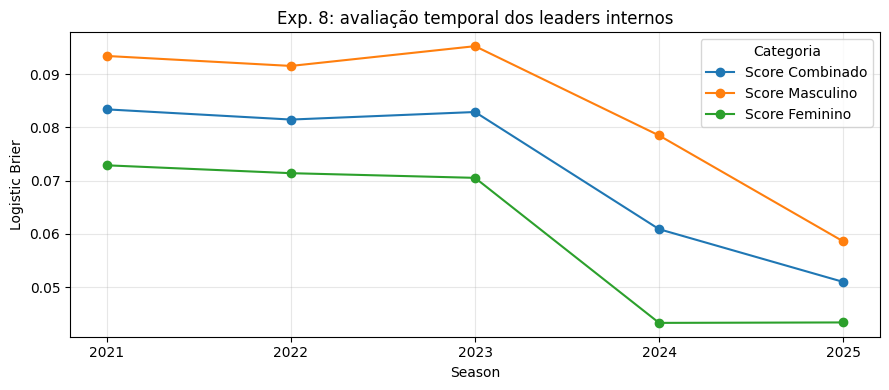

In [17]:
nomes_exp7 = {"linear": "Regressão Linear", "random_forest": "Random Forest", "xgboost": "XGBoost"}
comparacao = pd.DataFrame([
    {"Modelo/Experimento": "Exp. 7 - " + nomes_exp7[nome], "Logistic Brier médio": media}
    for nome, media in REFERENCIA_EXP7["medias"].items()
] + [{"Modelo/Experimento": "Exp. 8 - H2O AutoML", "Logistic Brier médio": avaliacao["media"]}])
display(comparacao.style.format({"Logistic Brier médio": "{:.8f}"}).highlight_min(
    subset=["Logistic Brier médio"], color="#d9ead3"))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
tabela_scores.plot(marker="o", ax=ax)
ax.set_ylabel("Logistic Brier")
ax.set_title("Exp. 8: avaliação temporal dos leaders internos")
ax.set_xticks(ANOS_VALIDACAO)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## Modelos escolhidos pelo AutoML

Frequência de famílias entre os dez leaders e um leaderboard de exemplo, ordenado
pela RMSE interna. RMSLE pode ser NaN porque o alvo contém margens negativas;
essa métrica não participa da seleção. Os demais leaderboards ficam em `avaliacao`.


In [18]:
display(leaders)
frequencias = leaders.groupby(["Algoritmo", "Categoria"]).size().unstack(fill_value=0)
frequencias["Total"] = frequencias.sum(axis=1)
display(frequencias.sort_values("Total", ascending=False))
EXEMPLO_FOLD = f"M_{ANOS_VALIDACAO[0]}"
display(avaliacao["leaderboards"][EXEMPLO_FOLD].head(10))
display(avaliacao["folds"].query("Categoria == 'M' and AnoValidacao == @ANOS_VALIDACAO[0]"))


,Season,Categoria,model_id,Algoritmo,RMSE_CV
0,2021,M,GLM_1_AutoML_13_20261021_152401,glm,11.176264
1,2021,W,GLM_1_AutoML_14_20261021_152435,glm,12.129405
2,2022,M,GLM_1_AutoML_15_20261021_152504,glm,11.238888
3,2022,W,GLM_1_AutoML_16_20261021_152538,glm,12.275575
4,2023,M,GLM_1_AutoML_17_20261021_152609,glm,11.311999
5,2023,W,GLM_1_AutoML_18_20261021_152644,glm,12.289662
6,2024,M,GLM_1_AutoML_19_20261021_152716,glm,11.374852
7,2024,W,StackedEnsemble_BestOfFamily_1_AutoML_20_20261...,stackedensemble,12.291486
8,2025,M,GLM_1_AutoML_21_20261021_152825,glm,11.456158
9,2025,W,GLM_1_AutoML_22_20261021_152902,glm,12.146348


Categoria,M,W,Total
Algoritmo,,,
glm,5,4,9
stackedensemble,0,1,1


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_13_20261021_152401,11.176264,124.908880,8.806822,NaN,124.908880
1,StackedEnsemble_BestOfFamily_1_AutoML_13_20261...,11.185684,125.119523,8.792095,NaN,125.119523
2,StackedEnsemble_AllModels_1_AutoML_13_20261021...,11.243955,126.426515,8.825528,NaN,126.426515
3,GBM_grid_1_AutoML_13_20261021_152401_model_45,11.356988,128.981182,8.896911,NaN,128.981182
4,GBM_grid_1_AutoML_13_20261021_152401_model_52,11.404059,130.052554,8.953669,NaN,130.052554
5,GBM_grid_1_AutoML_13_20261021_152401_model_59,11.407908,130.140357,8.944507,NaN,130.140357
6,GBM_grid_1_AutoML_13_20261021_152401_model_42,11.421009,130.439436,8.995159,NaN,130.439436
7,GBM_grid_1_AutoML_13_20261021_152401_model_89,11.422904,130.482732,9.001126,NaN,130.482732
8,GBM_grid_1_AutoML_13_20261021_152401_model_33,11.426774,130.571163,8.942281,NaN,130.571163
9,GBM_grid_1_AutoML_13_20261021_152401_model_97,11.427571,130.589369,8.967045,NaN,130.589369


,Season,FoldInterno,Jogos,AnoValidacao,Categoria
0,2003,3,64,2021,M
1,2004,4,64,2021,M
2,2005,1,64,2021,M
3,2006,2,64,2021,M
4,2007,2,64,2021,M
5,2008,0,64,2021,M
6,2009,3,64,2021,M
7,2010,1,64,2021,M
8,2011,1,67,2021,M
9,2012,0,67,2021,M


## Treino final

Dois novos AutoML com todo o histórico até 2025, mesma configuração e folds agrupados.
Selecionamos os três primeiros modelos de cada leaderboard final pela RMSE interna.
Não é necessário repetir o treino. A avaliação oficial acima continua usando apenas o leader.


In [19]:
execucoes_finais, modelos_finais, resumo_finais, folds_finais = {}, {}, [], []
TOP_N = 3
try:
    for categoria, tabela in jogos.items():
        treino = tabela.loc[tabela.Season < TEMPORADA_PREVISAO].copy()
        assert treino.Season.max() == 2025
        assert treino.TeamA.isin(dados[categoria]["times"].TeamID).all()
        assert treino.TeamB.isin(dados[categoria]["times"].TeamID).all()
        execucao = treinar_automl(treino, features=FEATURES, ano_previsao=TEMPORADA_PREVISAO,
            nome=f"exp8_final_{categoria}", **CONFIG_AUTOML)
        execucoes_finais[categoria] = execucao
        folds_finais.append(execucao["folds"].assign(Categoria=categoria))
    n_submissions = min(TOP_N, *[len(r["leaderboard"]) for r in execucoes_finais.values()])
    if n_submissions < TOP_N:
        print(f"Há modelos suficientes nas duas categorias para {n_submissions} submissões.")
    assert n_submissions >= 1
    for categoria, execucao in execucoes_finais.items():
        modelos_finais[categoria] = {}
        for posicao, linha in enumerate(execucao["leaderboard"].head(n_submissions).itertuples(index=False), start=1):
            modelo = h2o.get_model(linha.model_id)
            modelos_finais[categoria][posicao] = AdaptadorH2O(modelo, FEATURES)
            if posicao == 1:
                assert modelo.model_id == execucao["model_id"]
            resumo_finais.append({"Posicao": posicao, "Categoria": categoria,
                "model_id": modelo.model_id, "Algoritmo": modelo.algo, "RMSE_CV": float(linha.rmse)})
    for posicao in range(1, n_submissions + 1):
        assert modelos_finais["M"][posicao].leader.model_id != modelos_finais["W"][posicao].leader.model_id
except BaseException:
    for execucao in execucoes_finais.values():
        limpar_execucao(execucao)
    raise
display(pd.DataFrame(resumo_finais))



15:29:37.886: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.


15:30:16.72: Fold column FoldInterno will be used for cross-validation. nfolds parameter will be ignored.



,Posicao,Categoria,model_id,Algoritmo,RMSE_CV
0,1,M,GLM_1_AutoML_23_20261021_152937,glm,11.450129
1,2,M,StackedEnsemble_BestOfFamily_1_AutoML_23_20261...,stackedensemble,11.468972
2,3,M,StackedEnsemble_AllModels_1_AutoML_23_20261021...,stackedensemble,11.506305
3,1,W,GLM_1_AutoML_24_20261021_153016,glm,12.314785
4,2,W,StackedEnsemble_BestOfFamily_1_AutoML_24_20261...,stackedensemble,12.417494
5,3,W,StackedEnsemble_AllModels_1_AutoML_24_20261021...,stackedensemble,12.451813


## Submissions 2026 — top 3

Cada CSV combina a mesma posição dos leaderboards: 1º M + 1º W, 2º M + 2º W,
3º M + 3º W. São alternativas por ranking interno, não os três melhores pares
medidos pela Logistic Brier externa. Podem pertencer à mesma família de algoritmo.

Mesmas features e fallback do Exp. 7; margens brutas, sem sigmoid ou clipping.
Registramos os IDs dos modelos usados e liberamos todos somente após gerar os CSVs.


In [20]:
sample_submission = dados["M"]["sample_submission"]
confrontos = preparar_confrontos(
    sample_submission, seeds["M"], seeds["W"],
    dados["M"]["times"]["TeamID"], dados["W"]["times"]["TeamID"],
    temporada=TEMPORADA_PREVISAO,
)
stats_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)]
    for stats in estatisticas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas(confrontos, stats_2026, permitir_ausentes=True)
detalhes_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)] for stats in detalhadas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas_detalhadas(confrontos, detalhes_2026, permitir_ausentes=True)
participantes = confrontos["TemDuasSeeds"]
assert (confrontos["TeamA"] < confrontos["TeamB"]).all()
assert np.isfinite(confrontos.loc[participantes, FEATURES].to_numpy()).all()
stats_index = stats_2026.set_index(["Season", "TeamID"])
for nome in ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]:
    pares = confrontos.loc[participantes]
    a = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[f"{nome}Diff"], a - b)

lookup = detalhes_2026.set_index(["Season", "TeamID"])
pares = confrontos.loc[participantes]
for nome in ESTATISTICAS_DETALHADAS:
    a = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[nome + "Diff"], a - b)


arquivos_submission, resumo_submissions = {}, []
try:
    for posicao in range(1, n_submissions + 1):
        modelo_m = modelos_finais["M"][posicao]
        modelo_w = modelos_finais["W"][posicao]
        previsoes = prever_confrontos(confrontos, modelo_m, modelo_w, features=FEATURES)
        assert len(previsoes) == len(sample_submission)
        assert previsoes.ID.equals(sample_submission.ID)
        assert np.isfinite(previsoes.Pred).all()
        assert previsoes.loc[~participantes, "Pred"].eq(0).all()
        caminho = salvar_submission(previsoes, sample_submission,
            raiz / "submissions" / f"submission_exp8_h2o_automl_top{posicao}_2026.csv")
        arquivos_submission[posicao] = caminho
        resumo_submissions.append({"Posicao": posicao, "Arquivo": caminho.name,
            "ModeloM": modelo_m.leader.model_id, "ModeloW": modelo_w.leader.model_id,
            "Linhas": len(previsoes), "ParesParticipantes": int(participantes.sum()),
            "MinPred": previsoes.Pred.min(), "MaxPred": previsoes.Pred.max()})
    display(pd.DataFrame(resumo_submissions))
finally:
    for execucao in execucoes_finais.values():
        limpar_execucao(execucao)
    modelos_finais.clear()


,Posicao,Arquivo,ModeloM,ModeloW,Linhas,ParesParticipantes,MinPred,MaxPred
0,1,submission_exp8_h2o_automl_top1_2026.csv,GLM_1_AutoML_23_20261021_152937,GLM_1_AutoML_24_20261021_153016,132133,4556,-51.590118,58.550749
1,2,submission_exp8_h2o_automl_top2_2026.csv,StackedEnsemble_BestOfFamily_1_AutoML_23_20261...,StackedEnsemble_BestOfFamily_1_AutoML_24_20261...,132133,4556,-51.328485,58.812413
2,3,submission_exp8_h2o_automl_top3_2026.csv,StackedEnsemble_AllModels_1_AutoML_23_20261021...,StackedEnsemble_AllModels_1_AutoML_24_20261021...,132133,4556,-50.434939,56.235022


## Registro

Resultados ficam nas saídas do notebook; somente os CSVs são salvos no projeto.


In [21]:
registro = {
    "experimento": EXPERIMENTO, "features": FEATURES, "inicio_detalhado": INICIO_DETALHADO,
    "anos_validacao": ANOS_VALIDACAO, "temporada_previsao": TEMPORADA_PREVISAO,
    "limite_daynum_2026": LIMITE_DAYNUM_PREVISAO, "config_automl": CONFIG_AUTOML,
    "sort_metric": "RMSE", "stopping_metric": "RMSE", "max_runtime_secs": 0,
    "n_threads": N_THREADS, "max_mem_size": MAX_MEM_SIZE, "ambiente_h2o": ambiente_h2o,
    "media_logistic_brier": avaliacao["media"], "scores_anuais": scores_anuais.to_dict(orient="records"),
    "leaders": leaders.to_dict(orient="records"), "frequencias": frequencias.reset_index().to_dict(orient="records"),
    "folds_internos": avaliacao["folds"].to_dict(orient="records"),
    "modelos_finais_selecionados": resumo_finais, "folds_finais": pd.concat(folds_finais).to_dict(orient="records"),
    "comparacao": comparacao.to_dict(orient="records"), "referencia_exp7": REFERENCIA_EXP7,
    "versoes": {p: version(p) for p in ["h2o", "numpy", "pandas", "scipy", "scikit-learn"]},
    "top_n": TOP_N, "regra_submission": "Mesma posicao M/W no leaderboard interno por RMSE",
    "arquivos_submission": {str(posicao): str(path.relative_to(raiz)) for posicao, path in arquivos_submission.items()},
    "resumo_submissions": resumo_submissions,
}
display(registro)


{'experimento': 'exp8_h2o_automl',
 'features': ['SeedDif',
  'WinRateDiff',
  'AvgPointsForDiff',
  'AvgPointsAgainstDiff',
  'OppWinRateDiff',
  'FGPercentageDiff',
  'ThreePointPercentageDiff',
  'FTPercentageDiff',
  'AssistsPerGameDiff',
  'OffensiveReboundsPerGameDiff',
  'DefensiveReboundsPerGameDiff',
  'TurnoversPerGameDiff',
  'StealsPerGameDiff',
  'BlocksPerGameDiff'],
 'inicio_detalhado': {'M': 2003, 'W': 2010},
 'anos_validacao': [2021, 2022, 2023, 2024, 2025],
 'temporada_previsao': 2026,
 'limite_daynum_2026': 134,
 'config_automl': {'seed': 42,
  'max_models': 100,
  'n_folds': 5,
  'exclude_algos': ['DeepLearning', 'XGBoost']},
 'sort_metric': 'RMSE',
 'stopping_metric': 'RMSE',
 'max_runtime_secs': 0,
 'n_threads': 2,
 'max_mem_size': '4G',
 'ambiente_h2o': {'h2o_version': '3.46.0.12',
  'cluster_version': '3.46.0.12',
  'xgboost_disponivel': False,
  'exclude_algos': ['DeepLearning', 'XGBoost'],
  'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias

## Encerramento opcional

Os modelos já foram removidos; encerre o cluster quando não for mais utilizá-lo.


In [22]:
ENCERRAR_H2O = False
if ENCERRAR_H2O:
    h2o.cluster().shutdown(prompt=False)